# 07 — Inferencia e Intervalos de Confianca

**Objetivos de aprendizagem:** estimar parâmetros e quantificar incerteza por t de Student e bootstrap

**Pré-requisitos:** Notebooks 04–06

**Origem:** Slides, aula 09, páginas 180–200; Tabela T como referência; aprofundamento: bootstrap. Conteúdos adicionais estão identificados como **Aprofundamento**.

**Convenção:** `datasets/` reúne dados de entrada; `outputs/` reúne resultados. Dados inventados para demonstrações são sempre identificados como *sintéticos*.

### Materiais complementares

- [Guia Técnico](./reference_materials/07_inferencia_e_intervalos_de_confianca.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_inferencia_e_intervalos_de_confianca.pdf)
- [Tabela t — consulta](./reference_materials/tabela_t.pdf)


## Preparação do ambiente

Execute a célula abaixo. Os notebooks são independentes e não dependem de variáveis definidas em outros arquivos.

> **Resultados reproduzíveis:** gráficos PNG e tabelas CSV selecionados são gravados automaticamente em `outputs/` ao executar as células na ordem. Os arquivos em `datasets/` são preservados. Esta área utiliza Matplotlib, não o renderer `iframe` do Plotly.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Execute o JupyterLab com o diretório desta disciplina como raiz.
BASE = Path.cwd()
DATASETS = BASE / "datasets"
OUTPUTS = BASE / "outputs"
DATASETS.mkdir(parents=True, exist_ok=True)
OUTPUTS.mkdir(parents=True, exist_ok=True)

def ler_dataset(nome):
    caminho = DATASETS / nome
    if not caminho.is_file():
        raise FileNotFoundError(f"Dataset não encontrado: {caminho}. Abra o JupyterLab na raiz da disciplina.")
    return pd.read_csv(caminho)

RNG = np.random.default_rng(42)

## 1. Estimação pontual e incerteza

Estimador é regra amostral; estimativa é o número obtido. Um intervalo de confiança frequentista tem cobertura de longo prazo em repetições do procedimento, não probabilidade posterior de o parâmetro fixo pertencer ao intervalo observado.

In [2]:
from scipy import stats
x=RNG.normal(50,10,35) # dados sintéticos
n=len(x);media=x.mean();s=x.std(ddof=1);se=s/np.sqrt(n)
print('estimativa',media,'desvio amostral',s,'erro padrão',se)

estimativa 50.437034335421004 desvio amostral 8.312701677366368 erro padrão 1.4051030381830125


## 2. Intervalo t para média

Com dados independentes aproximadamente normais (ou amostras em que aproximações adequadas se sustentem), IC bilateral da média = média ± t_(1−α/2, n−1) × s/√n. Verifique condições de uso.

In [3]:
alpha=.05
crit=stats.t.ppf(1-alpha/2,df=n-1)
ici=(media-crit*se,media+crit*se)
print('t crítico',crit,'IC de 95%',ici)
assert ici[0]<media<ici[1]

t crítico 2.0322445093177186 IC de 95% (np.float64(47.58152140104793), np.float64(53.29254726979408))


## 3. Tabela T manual

A tabela histórica exibe valores críticos por graus de liberdade e probabilidade bilateral. A linha `gl=10`, na coluna de 5% bicaudal, apresenta aproximadamente 2,228: compare com SciPy.

In [4]:
valor=stats.t.ppf(.975,10)
print('SciPy t(10), 95% bilateral:',valor)
assert abs(valor-2.2281)<.001

SciPy t(10), 95% bilateral: 2.228138851986274


## 4. Bootstrap percentil — aprofundamento

O bootstrap reamostra com reposição da amostra observada. Um intervalo percentil é fácil de implementar, mas pode ter cobertura ruim com amostras pequenas, forte assimetria ou estatísticas não regulares.

IC bootstrap percentil [47.79105016 53.18911579]


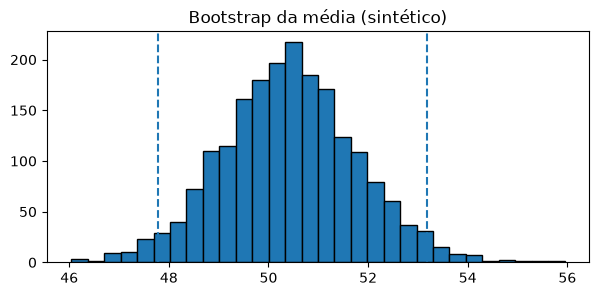

In [5]:
B=2000;boot=np.array([RNG.choice(x,size=n,replace=True).mean() for _ in range(B)])
lim=np.quantile(boot,[.025,.975]);print('IC bootstrap percentil',lim)
fig,ax=plt.subplots(figsize=(7,3));ax.hist(boot,bins=30,edgecolor='black');ax.axvline(lim[0],ls='--');ax.axvline(lim[1],ls='--');ax.set(title='Bootstrap da média (sintético)');fig.savefig(OUTPUTS / '07_distribuicao_bootstrap.png', dpi=160, bbox_inches='tight');plt.show()

In [6]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
pd.DataFrame({'media_bootstrap':boot}).to_csv(OUTPUTS / '07_medias_bootstrap.csv',index=False,encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


## 5. Simulação de cobertura

A cobertura é propriedade do procedimento sob o modelo gerador. Em muitas amostras, cerca de 95% dos intervalos de 95% conterão o verdadeiro μ; não necessariamente exatamente 95% numa simulação finita.

In [7]:
sim=RNG.normal(10,3,size=(500,30));med=sim.mean(axis=1);ses=sim.std(axis=1,ddof=1)/np.sqrt(30)
tcrit=stats.t.ppf(.975,29);cobertura=np.mean((med-tcrit*ses<=10)&(med+tcrit*ses>=10))
print('Cobertura observada em 500 repetições:',cobertura)
assert .85<cobertura<1

Cobertura observada em 500 repetições: 0.948


In [8]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
pd.DataFrame({'estimativa':[media], 'ic_t_inferior':[ici[0]],'ic_t_superior':[ici[1]],'ic_bootstrap_inferior':[lim[0]],'ic_bootstrap_superior':[lim[1]],'cobertura_simulada':[cobertura]}).to_csv(OUTPUTS / '07_resumo_intervalos.csv',index=False,encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


### Exercício resolvido — Efeito do tamanho da amostra na margem

**Solução comentada:**

In [9]:
m30=stats.t.ppf(.975,29)*3/np.sqrt(30)
m120=stats.t.ppf(.975,119)*3/np.sqrt(120)
print('margem n=30',m30,'n=120',m120)
assert m120<m30

margem n=30 1.1202184102742996 n=120 0.5422726842243292


**Interpretação:** Em condições comparáveis, mais observações reduzem o erro padrão e estreitam intervalos.

## Erros comuns e limites

Não interprete 95% como probabilidade posterior de μ em um intervalo fixo, nem use bootstrap como substituto automático da análise do desenho amostral.

## Consulta Rápida

`stats.t.ppf(0.975,df=n-1)` · `stats.t.interval(0.95,df=n-1,loc=x.mean(),scale=stats.sem(x))` · `np.quantile(boot,[.025,.975])`.

## Autoavaliação

Antes de seguir, explique com suas palavras: **qual é a pergunta estatística, qual método responde a ela, quais pressupostos devem ser verificados e o que não podemos concluir?**

## Aprofundamento v2 — Cobertura, precisão e significado de IC

Um intervalo de confiança frequentista de 95% descreve um **procedimento de longo prazo**: sob o modelo e condições assumidos, cerca de 95% dos intervalos calculados em muitas amostras cobririam o parâmetro fixo. Não significa 95% de probabilidade de o parâmetro já fixo pertencer ao intervalo observado.

O bootstrap percentil pode ser impreciso com amostras pequenas, estatísticas muito assimétricas e forte dependência; o procedimento deve refletir a unidade amostral.

In [10]:
from scipy import stats
rng_cobertura=np.random.default_rng(2026)
rep=1200;n_cob=25;mu_real=8;sd_real=3
amostras=rng_cobertura.normal(mu_real,sd_real,size=(rep,n_cob))
medias=amostras.mean(axis=1)
erros=amostras.std(axis=1,ddof=1)/np.sqrt(n_cob)
tcrit=stats.t.ppf(.975,n_cob-1)
cobre=((medias-tcrit*erros<=mu_real)&(mu_real<=medias+tcrit*erros))
print('Cobertura Monte Carlo:',round(cobre.mean(),3))
assert .90 < cobre.mean() < .99

Cobertura Monte Carlo: 0.955


### Exercício resolvido

**Pergunta:** uma pesquisa obteve `IC95% = [7, 11]`. É correto afirmar que há 95% de chance de o parâmetro fixo estar nesse intervalo específico?

**Solução:** não na interpretação frequentista. O nível de 95% caracteriza a cobertura do procedimento sob repetição; com uma amostra, o intervalo contém ou não o parâmetro.